# 03 · QFT 与相位估计：把相位写进比特，再读出来

对应讲义实验 B · 约 45 分钟 · 前置：01 编程基础

量子傅里叶变换（QFT）把整数写进相位；相位估计（QPE）用逆 QFT 把相位读出来。QPE 是 Shor 算法和许多容错算法的核心子程序。

**学完本节，你将能够**
- 读懂 QFT 线路，并用经典的离散傅里叶变换验证它；
- 说清 QFT 与经典 FFT 的本质区别；
- 实现相位估计，破解一个“神秘量子门”的相位。

In [1]:
import sys; sys.path.insert(0, "..")  # 仅参考答案需要：mqlab 位于上一级目录
import numpy as np
import matplotlib.pyplot as plt
from mindquantum import Circuit, UN, H, X, Power, PhaseShift, Measure, Simulator, qft
from mqlab import check

## 1. QFT 线路

`qft(range(n))` 生成 n 比特 QFT 线路：每个比特一个 H，加上 $n(n-1)/2$ 个受控相位门，末尾用 SWAP 交换比特顺序。

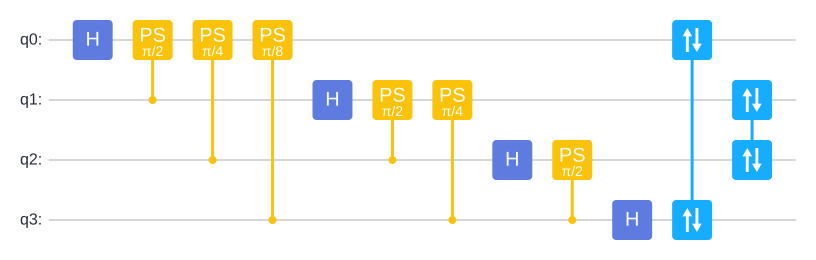

In [2]:
qft(range(4)).svg()

QFT 把整数 x 写进相位。以 $|101\rangle$（x = 5）为例：输出的 8 个振幅大小完全相同，信息全在相位里。

In [3]:
sim = Simulator('mqvector', 3)
sim.set_qs(np.eye(8)[5])                       # |101⟩
sim.apply_circuit(qft(range(3)))
out = sim.get_qs()
print('振幅的模：  ', np.abs(out).round(3))
print('相位（圈）：', (np.angle(out) / (2 * np.pi) % 1).round(3))

振幅的模：   [0.354 0.354 0.354 0.354 0.354 0.354 0.354 0.354]
相位（圈）： [0.    0.5   0.25  0.75  0.625 0.125 0.875 0.375]


所有振幅的模都是 $1/\sqrt{8}$：直接测量只能得到均匀随机的比特串。要用上这些相位，还需要后续的干涉——这就是第 4 节相位估计要做的事。

## 2. 验证：QFT 就是离散傅里叶变换

调试量子程序的好习惯：用经典方法验证。QFT 对振幅做的正是离散傅里叶变换（DFT）。教科书把 q0 当作最高位，而 MindSpore Quantum 使用小端序，因此比较时要在前后各做一次比特反转。

In [4]:
n = 4
rng = np.random.default_rng(7)
psi = rng.normal(size=2 ** n) + 1j * rng.normal(size=2 ** n)
psi /= np.linalg.norm(psi)                     # 随机量子态

sim = Simulator('mqvector', n)
sim.set_qs(psi)
sim.apply_circuit(qft(range(n)))               # 量子线路

rev = [int(f'{i:0{n}b}'[::-1], 2) for i in range(2 ** n)]   # 比特反转
ref = np.fft.ifft(psi[rev], norm='ortho')[rev]              # 经典 DFT
print(np.allclose(sim.get_qs(), ref))

True


### 练习 1 · 逆 QFT 的经典参考

补全 `inverse_qft_reference(psi)`：用 NumPy 计算 `qft(range(n)).hermitian()` 作用在 psi 上的结果。

In [5]:
def inverse_qft_reference(psi):
    n = int(np.log2(len(psi)))
    # 练习 1
    ### BEGIN SOLUTION
    rev = [int(f'{i:0{n}b}'[::-1], 2) for i in range(2 ** n)]
    return np.fft.fft(psi[rev], norm='ortho')[rev]
    ### STUDENT: return ...
    ### END SOLUTION

check.inverse_qft_reference(inverse_qft_reference)

✅ 通过：n = 2、3、4 的随机态都与逆 QFT 线路一致


## 3. QFT 与 FFT：快在哪里，代价是什么

| | 经典 FFT | 量子 QFT |
|---|---|---|
| 运算量 | $O(n\,2^n)$ 次运算 | $O(n^2)$ 个量子门 |
| 结果 | $2^n$ 个系数全部可读 | 藏在振幅里，测量只得到一个比特串 |

QFT 不是“更快的 FFT”：它无法输出傅里叶系数。它的价值在于作为子程序，把相位信息转换成可以测量的比特串。

## 4. 挑战 · 用相位估计破解神秘量子门

神秘门 U 满足 $U|1\rangle = e^{2\pi i\varphi}|1\rangle$，求相位 φ。线路分四步（计数比特 $q_0 \ldots q_{n-1}$，目标比特 $q_n$）：

1. 计数比特全部作用 H；目标比特用 X 制备到本征态 $|1\rangle$；
2. 受控 $U^{2^k}$：**最上面的计数比特控制最高次幂**，即 $q_i$ 控制 $U^{2^{n-1-i}}$。`Power(U, m).on(目标, 控制)` 表示受控的 $U^m$；
3. 对计数比特作用逆 QFT：`qft(range(n)).hermitian()`；
4. 测量计数比特。

In [6]:
def qpe(U, n):
    circ = Circuit()
    # 挑战：按上面四步搭建线路
    ### BEGIN SOLUTION
    circ += UN(H, n)
    circ += X.on(n)                                   # 目标比特 → 本征态 |1⟩
    for i in range(n):
        circ += Power(U, 2 ** i).on(n, n - 1 - i)     # q(n−1−i) 控制 U^(2^i)
    circ += qft(range(n)).hermitian()
    circ += UN(Measure(), n)
    ### END SOLUTION
    return circ

check.qpe(qpe)

✅ 通过：四个相位都被精确估计；按本题约定，读结果时要反转比特串


通过检查后，破解神秘相位：采样 100 次，取出现最多的比特串。教科书的线路按大端序给出 φ 的二进制，所以读结果时要反转比特串。

In [7]:
true_phi = 0.625
U = PhaseShift(2 * np.pi * true_phi)          # 神秘门
n = 3
circ = qpe(U, n)
if len(circ) == 0:
    print('请先完成挑战')
else:
    circ = circ.remove_measure() + UN(Measure(), n)
    res = Simulator('mqvector', n + 1).sampling(circ, shots=100, seed=1)
    bits = max(res.data, key=res.data.get)[::-1]      # 反转比特串
    print(res.data, '→ φ ≈', int(bits, 2) / 2 ** n)

{'101': 100} → φ ≈ 0.625


### 现场改一改：先预测，再运行

在上面破解神秘相位的代码上改三处，每一处先写下预测：

1. `true_phi = 0.375`：测到的比特串是？　A `011`　B `110`　C 两者各占一半
2. 去掉逆 QFT：测量结果会怎样？　A 仍是 `101`　B 8 种结果均匀出现　C 全是 `000`
3. `true_phi = 1 / 3`：得到的 φ 估计会怎样？　A 报错　B 总是 0.375　C 分散，峰值在 0.375

In [8]:
def sample_qpe(phi, n=3):
    circ = qpe(PhaseShift(2 * np.pi * phi), n)
    if len(circ) == 0:
        return '请先完成挑战'
    circ = circ.remove_measure() + UN(Measure(), n)
    return Simulator('mqvector', n + 1).sampling(circ, shots=100, seed=1).data

print('第 1 处：', sample_qpe(0.375))

no_iqft = UN(H, 3) + X.on(3)
for i in range(3):
    no_iqft += Power(U, 2 ** i).on(3, 2 - i)    # 与 qpe 相同，只是没有逆 QFT
no_iqft += UN(Measure(), 3)
print('第 2 处：', Simulator('mqvector', 4).sampling(no_iqft, shots=200, seed=1).data)

print('第 3 处：', sample_qpe(1 / 3))

第 1 处： {'110': 100}
第 2 处： {'000': 25, '001': 28, '010': 26, '011': 24, '100': 27, '101': 27, '110': 25, '111': 18}
第 3 处： {'000': 3, '001': 3, '010': 22, '100': 5, '101': 1, '110': 66}


<details><summary>答案</summary>

1. B：100 次都是 `110`，反转后为 `011`，即 φ = 3/8 = 0.375。φ = 0.625 的 `101` 是回文，看不出比特序是否处理正确。
2. B：8 种结果各约 25 次。相位信息仍在计数比特里，只是计算基测量看不见它；逆 QFT 的作用正是把相位变成比特。
3. C：结果分散，`110`（反转后 0.375）约占七成。下一节展开：计数比特越多，峰值越接近 1/3。
</details>

## 5. 延伸：相位无法用 n 位二进制精确表示时

φ = 1/3 不能写成有限位的二进制小数。此时结果不再确定，而是集中在最接近的 $k/2^n$ 附近；计数比特越多，估计越精确。

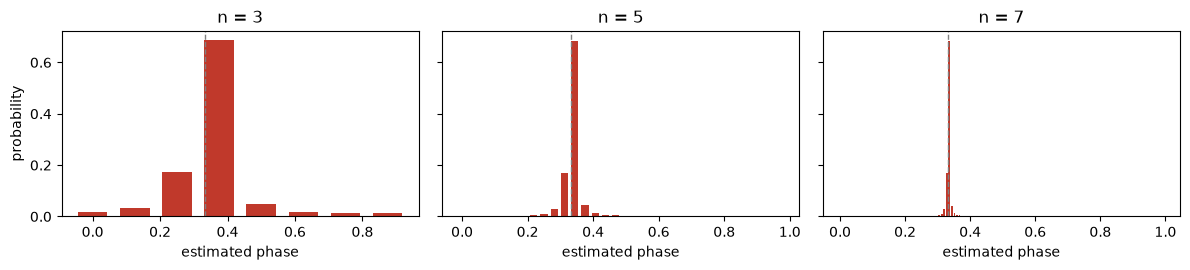

In [9]:
phi = 1 / 3
if len(qpe(U, 3)) == 0:
    print('请先完成挑战')
else:
    fig, axes = plt.subplots(1, 3, figsize=(12, 2.8), sharey=True)
    for ax, n in zip(axes, [3, 5, 7]):
        sim = Simulator('mqvector', n + 1)
        sim.apply_circuit(qpe(PhaseShift(2 * np.pi * phi), n).remove_measure())
        p = (np.abs(sim.get_qs()) ** 2).reshape(2, -1).sum(axis=0)   # 计数比特的分布
        est = [int(f'{i:0{n}b}'[::-1], 2) / 2 ** n for i in range(2 ** n)]
        ax.bar(est, p, width=0.7 / 2 ** n, color='#c0392b')
        ax.axvline(phi, color='0.5', ls='--', lw=1)
        ax.set_title(f'n = {n}')
        ax.set_xlabel('estimated phase')
    axes[0].set_ylabel('probability')
    plt.tight_layout()
    plt.show()

## 小结

- QFT 用 $O(n^2)$ 个门完成 $2^n$ 维的傅里叶变换，但结果在振幅里，无法直接读出。
- 相位估计用受控 $U^{2^k}$ 把相位写进计数比特，再用逆 QFT 读出；n 个计数比特给出 n 位二进制精度。
- Shor 算法分解大数，本质上就是对“模乘”门做相位估计。